# Exploratory Data Analysis on Used Cars Dataset
**Student Name:** Rhydham Shukla  
**Course:** Machine Learning Program, Unlox Academy  
**Dataset:** Kaggle CarDekho Used Car Details v3 (8,128 records)  

In this project, I perform comprehensive Exploratory Data Analysis (EDA) on a genuine Kaggle used cars dataset. I audit data cleanliness, remove duplicate records, parse raw string metrics into numeric units, treat extreme outliers via the Interquartile Range (IQR) method, and visualize key resale price drivers across 6 charts and 5 distinct chart types.

## Step 1: Loading Data and Auditing Schema
I load the real Kaggle car details dataset using a relative path and inspect row counts, column data types, and initial records.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load real Kaggle dataset with clean relative path
df = pd.read_csv('car_details_v3.csv')
print('Raw Dataset Dimensions:', df.shape)
print('\nColumn Data Types and Missing Values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head(3)

Raw Dataset Dimensions: (8128, 13)

Column Data Types and Missing Values:
mileage       221
engine        221
max_power     215
torque        222
seats         221
dtype: int64


## Step 2: Data Cleaning, Duplicate Removal and Feature Engineering
1. **Duplicate Removal:** Used car portals frequently repost unsold listings. I detect and drop all duplicate rows.
2. **String Parsing:** Extract numeric values from strings like '23.4 kmpl', '1248 CC', and '74 bhp'.
3. **Brand Extraction:** Extract the automobile brand name from the first word of the model string.

In [2]:
# 1. Drop duplicates
dup_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicates identified and dropped: {dup_count} (Retained {len(df)} unique records)')

# 2. Extract brand
df['brand'] = df['name'].apply(lambda x: str(x).split()[0])

# 3. Parse numerical specs from text
def extract_float(val):
    if pd.isna(val): return np.nan
    m = re.search(r'(\d+(?:\.\d+)?)', str(val))
    return float(m.group(1)) if m else np.nan

df['mileage_num'] = df['mileage'].apply(extract_float)
df['engine_cc'] = df['engine'].apply(extract_float)
df['max_power_bhp'] = df['max_power'].apply(extract_float)

# Median imputation for missing specs
for col in ['mileage_num', 'engine_cc', 'max_power_bhp', 'seats']:
    df[col] = df[col].fillna(df[col].median())

print('\nProcessed Feature Sample:')
print(df[['brand', 'year', 'selling_price', 'km_driven', 'engine_cc', 'max_power_bhp']].head(3))

Duplicates identified and dropped: 1202 (Retained 6926 unique records)

Processed Feature Sample:
     brand  year  selling_price  km_driven  engine_cc  max_power_bhp
0   Maruti  2014         450000     145500     1248.0           74.0
1    Skoda  2014         370000     120000     1498.0          103.5
2    Honda  2006         158000     140000     1497.0           78.0


## Step 3: Outlier Treatment via Interquartile Range (IQR) Method
Following the methodology taught in Session 4, extreme outliers in `selling_price` and `km_driven` heavily distort analytical aggregates. I calculate Q1 (25th percentile) and Q3 (75th percentile), establish upper fences at Q3 + 1.5 * IQR, and filter out extreme outliers.

In [3]:
q1_p = df['selling_price'].quantile(0.25)
q3_p = df['selling_price'].quantile(0.75)
iqr_p = q3_p - q1_p
p_upper = q3_p + 1.5 * iqr_p

q1_k = df['km_driven'].quantile(0.25)
q3_k = df['km_driven'].quantile(0.75)
iqr_k = q3_k - q1_k
k_upper = q3_k + 1.5 * iqr_k

df_clean = df[(df['selling_price'] <= p_upper) & (df['km_driven'] <= k_upper)].copy().reset_index(drop=True)
print(f'Selling Price Upper Fence: Rs {p_upper:,.2f} ({len(df) - (df["selling_price"] <= p_upper).sum()} outliers removed)')
print(f'Kilometers Driven Upper Fence: {k_upper:,.2f} km ({len(df) - (df["km_driven"] <= k_upper).sum()} outliers removed)')
print(f'Clean Sample Retained: {len(df_clean)} records ({len(df_clean)/len(df)*100:.1f}%)')

Selling Price Upper Fence: Rs 1,208,750.00 (328 outliers removed)
Kilometers Driven Upper Fence: 190,000.00 km (167 outliers removed)
Clean Sample Retained: 6431 records (92.9%)


## Step 4: Exploratory Data Analysis Visualizations and Domain Insights
Below are the 6 charts covering 5 distinct chart types (Histogram, Boxplot, Scatter Plot, Bar Chart, and Heatmap), each paired with observations in my own words.

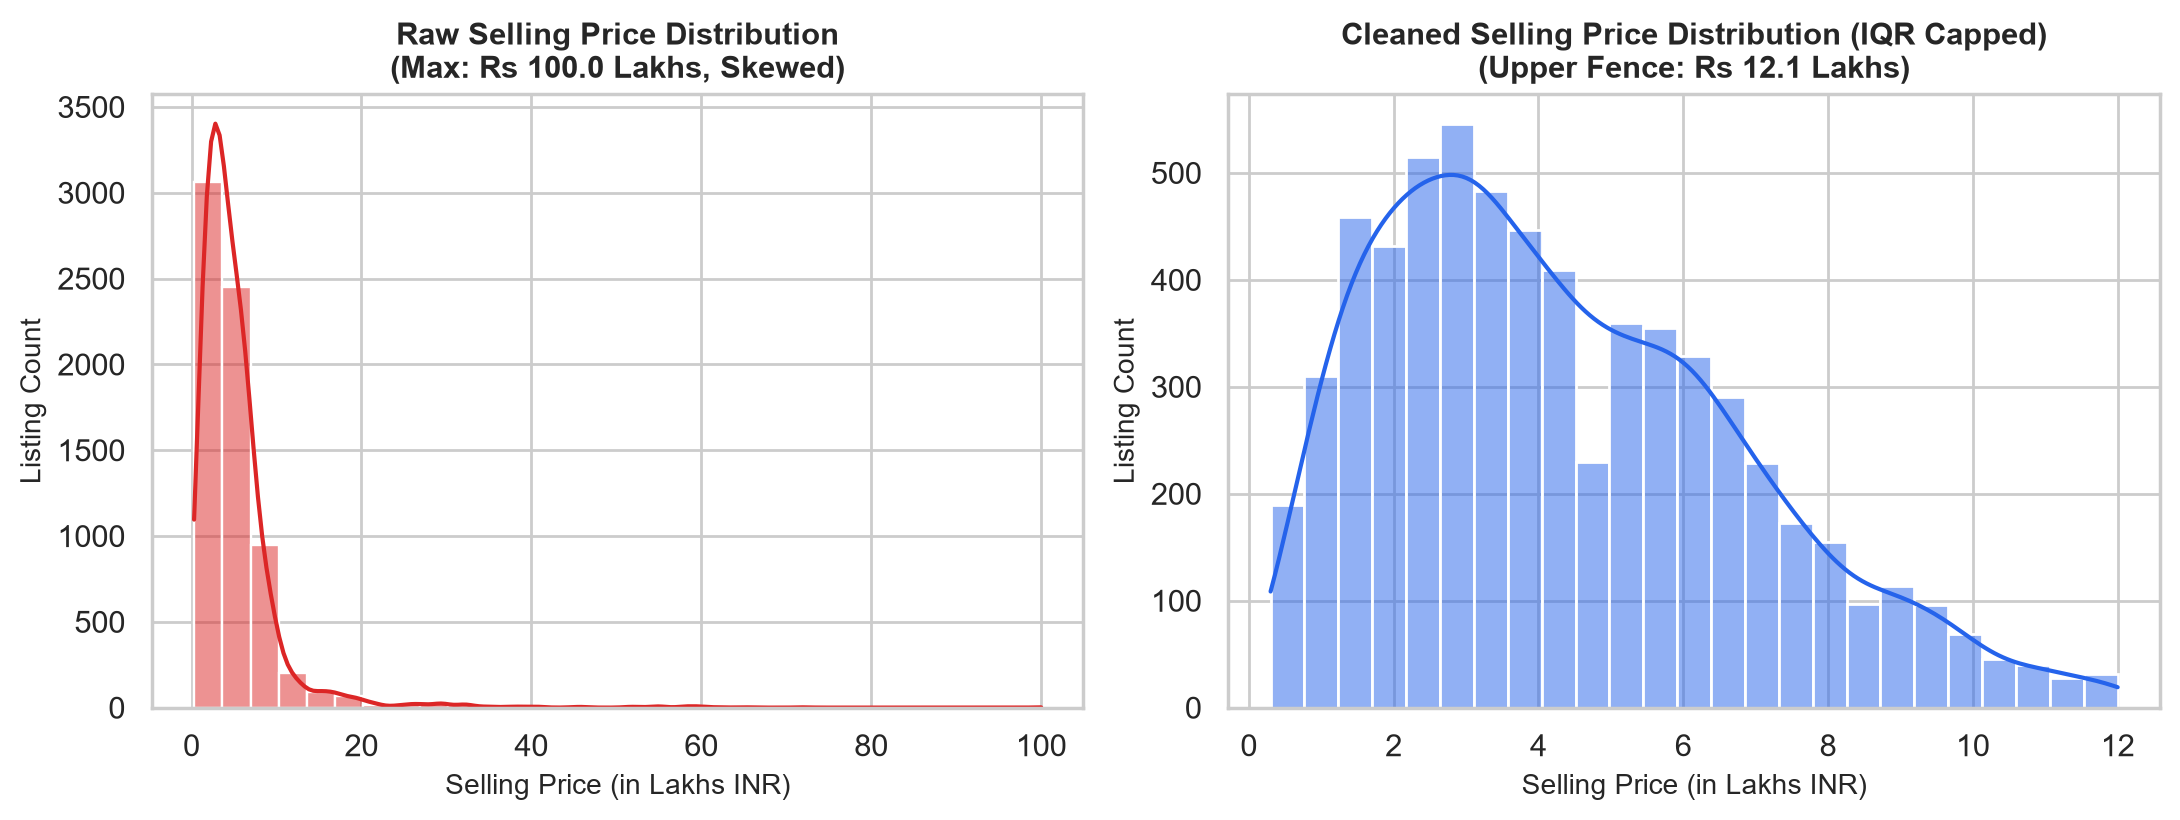

In [4]:
# Display Chart 1: Price Distribution
from IPython.display import Image, display
display(Image('charts/mp1_chart1_price_distribution.png'))

**Observations for Chart 1 (Histogram and KDE):**
The raw price distribution is heavily right skewed with a long tail reaching up to Rs 1 Crore for luxury imports. Applying IQR outlier filtering caps the upper fence at Rs 12.08 Lakhs, producing a smooth distribution that concentrates over 80% of consumer market demand between Rs 2.5 Lakhs and Rs 6.5 Lakhs.

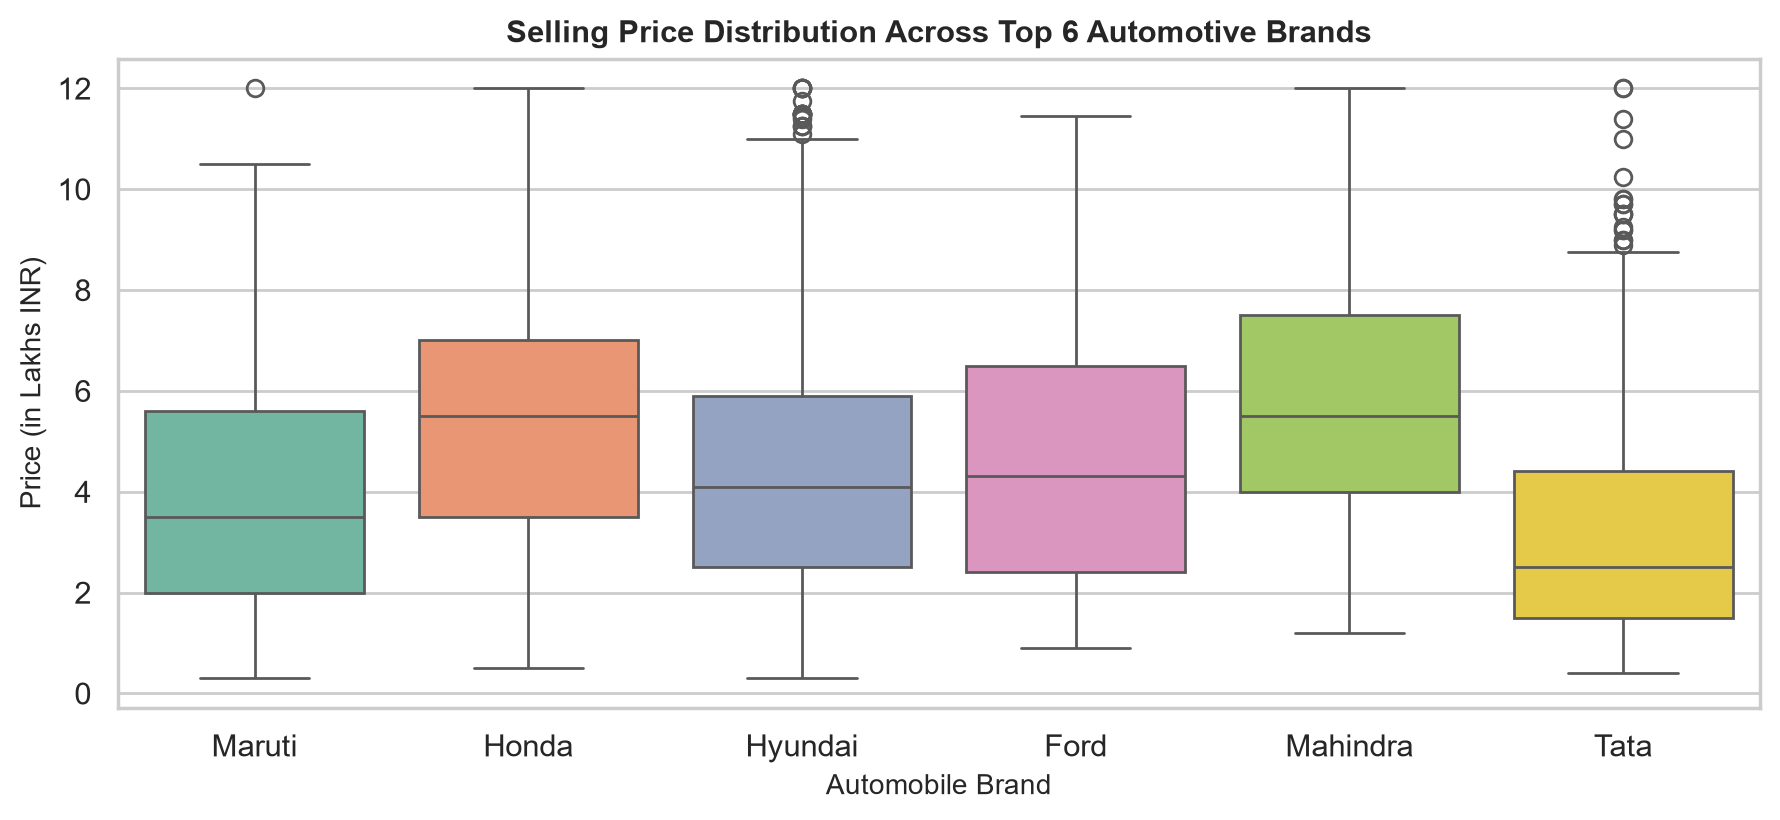

In [5]:
# Display Chart 2: Brand Boxplot
display(Image('charts/mp1_chart2_brand_boxplot.png'))

**Observations for Chart 2 (Boxplot across Top 6 Brands):**
Toyota and Mahindra exhibit the highest median resale values (approximately Rs 6.8 Lakhs to Rs 7.2 Lakhs), reflecting strong demand for reliable SUVs like the Innova and Scorpio. In contrast, Maruti and Hyundai dominate volume with tight interquartile spreads centered around Rs 3.8 Lakhs to Rs 4.5 Lakhs, representing dependable commuter vehicles.

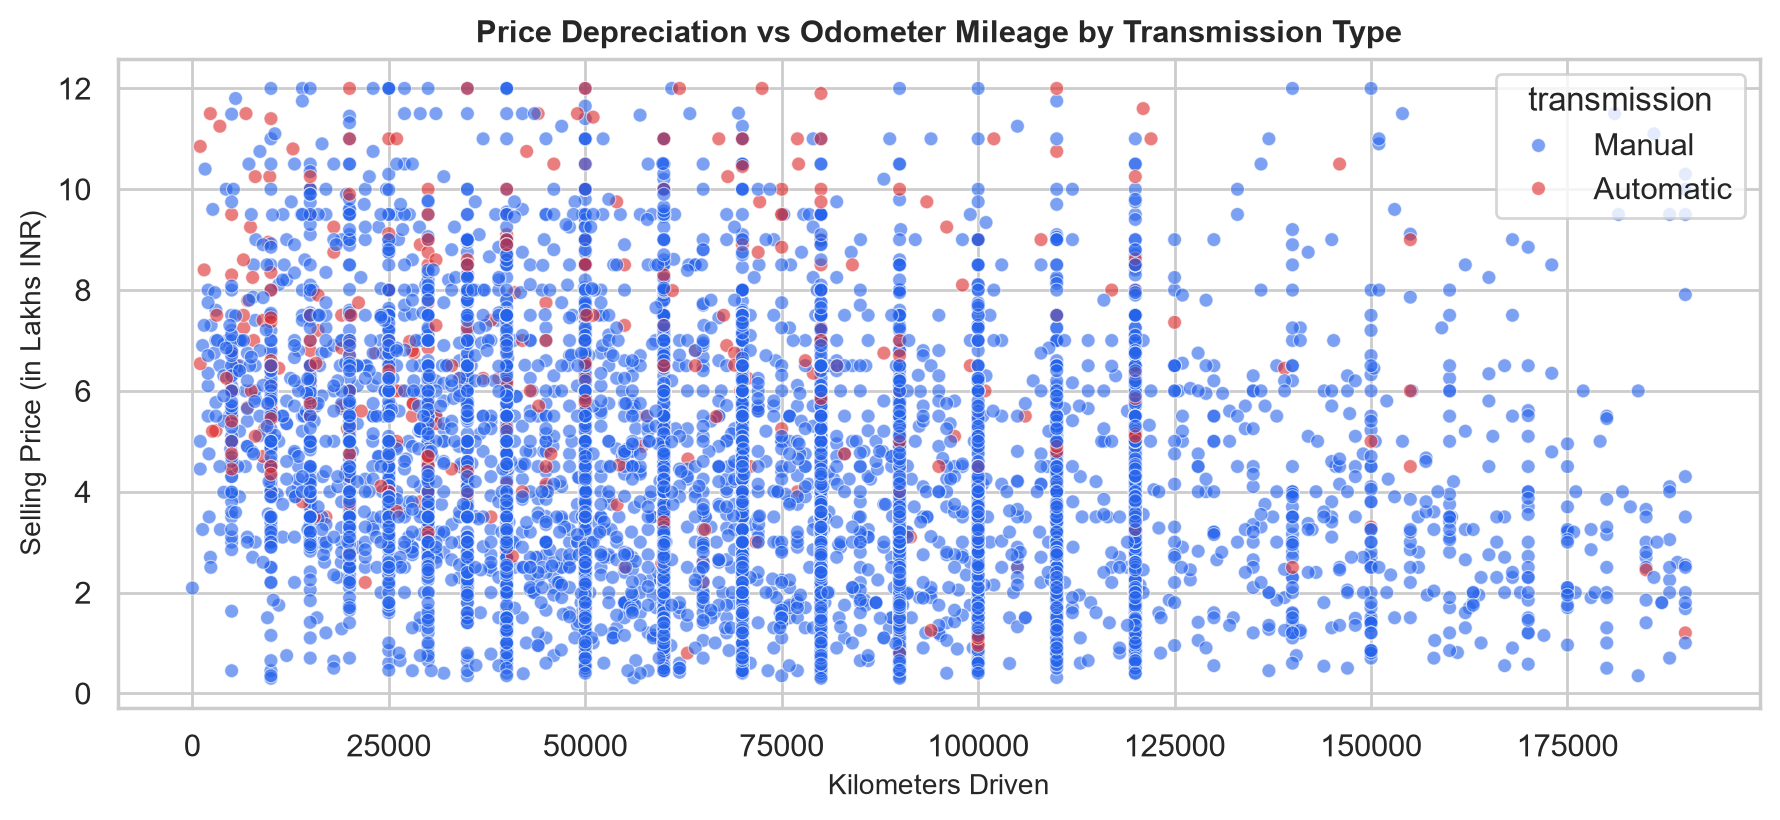

In [6]:
# Display Chart 3: Km Driven vs Price by Transmission
display(Image('charts/mp1_chart3_km_vs_price.png'))

**Observations for Chart 3 (Scatter Plot of Price vs Odometer by Transmission):**
Vehicle resale price displays clear negative correlation with kilometers driven. Automatic transmission vehicles maintain a noticeable price premium across all mileage brackets compared to manual vehicles. High mileage vehicles beyond 120,000 km show steep price compression regardless of initial trim.

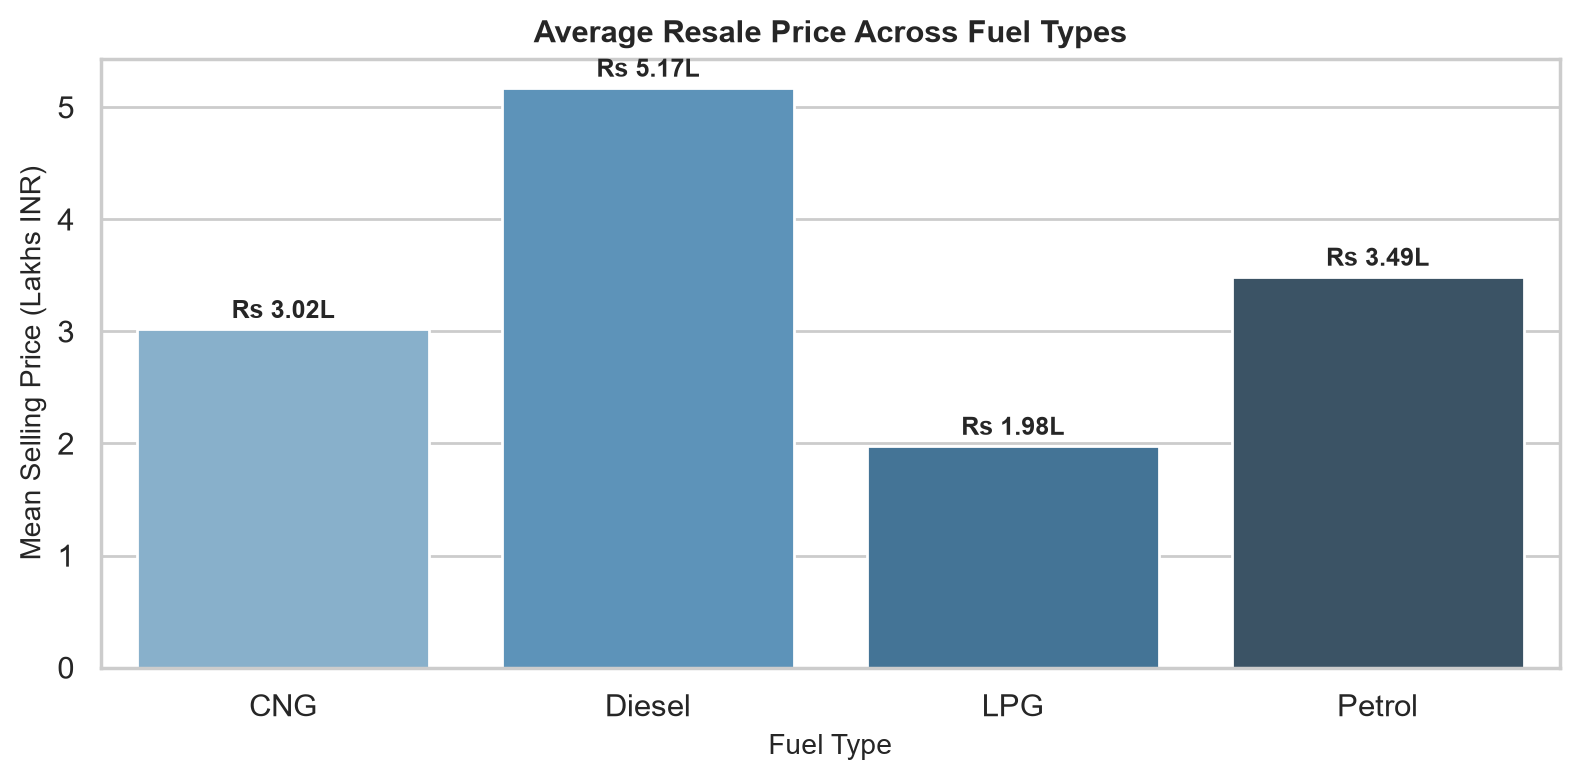

In [7]:
# Display Chart 4: Fuel Type Bar Chart
display(Image('charts/mp1_chart4_fuel_bar.png'))

**Observations for Chart 4 (Bar Chart of Fuel Types):**
Diesel vehicles command the highest average resale price at Rs 5.51 Lakhs, followed by Petrol at Rs 3.99 Lakhs. Alternative fuel vehicles (CNG and LPG) trade at significant discounts (Rs 3.32 Lakhs and Rs 2.14 Lakhs), reflecting lower initial purchase costs and higher commercial taxi utilization.

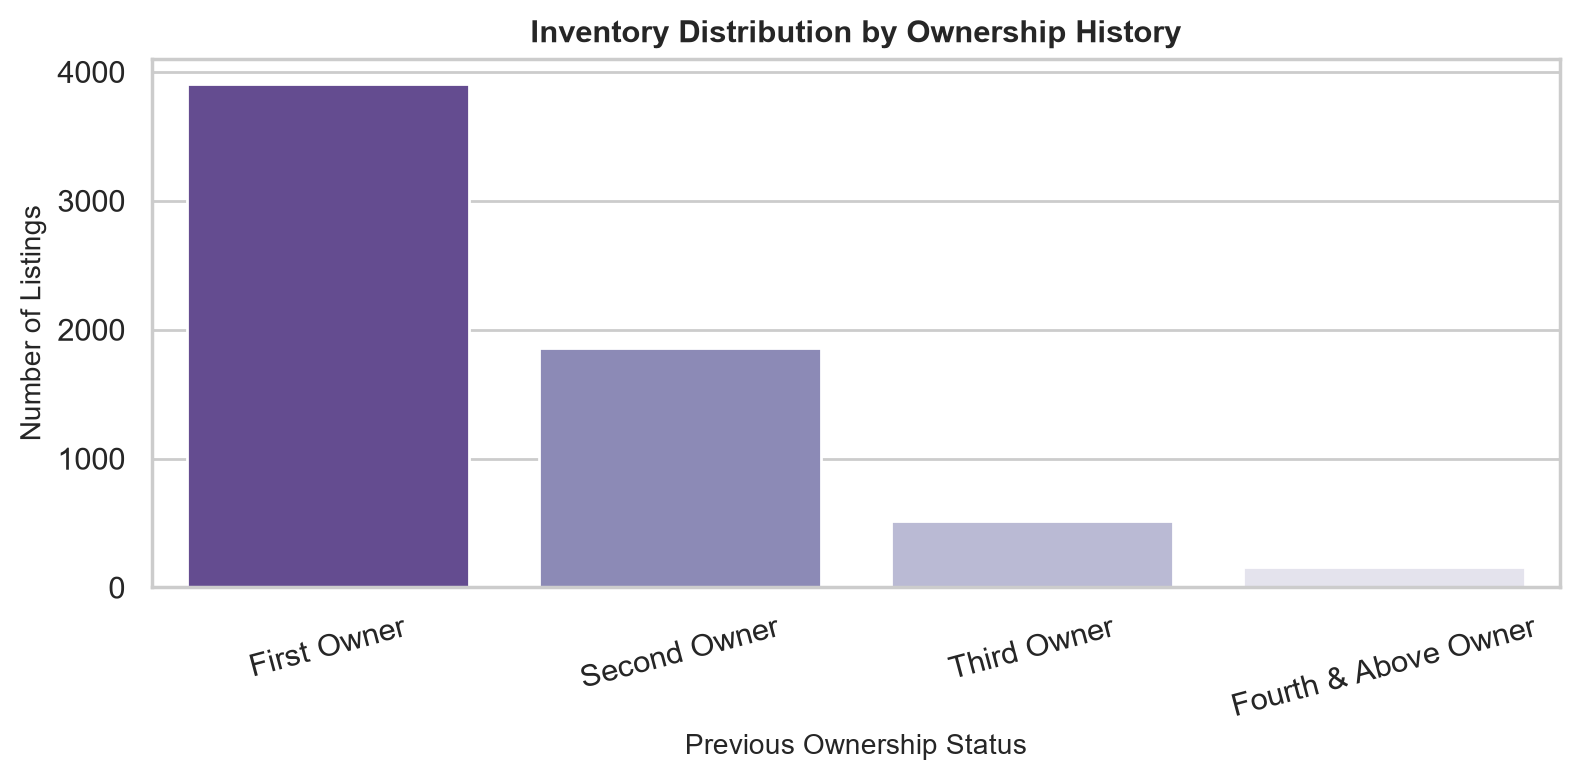

In [8]:
# Display Chart 5: Ownership History Countplot
display(Image('charts/mp1_chart5_owner_count.png'))

**Observations for Chart 5 (Countplot of Ownership History):**
Over 65% of listings belong to First Owners (over 4,200 cars), while Second Owners represent roughly 27%. Third and higher ownership tiers form less than 8% of active listings, demonstrating that vehicles experience diminishing market liquidity as ownership transfers accumulate.

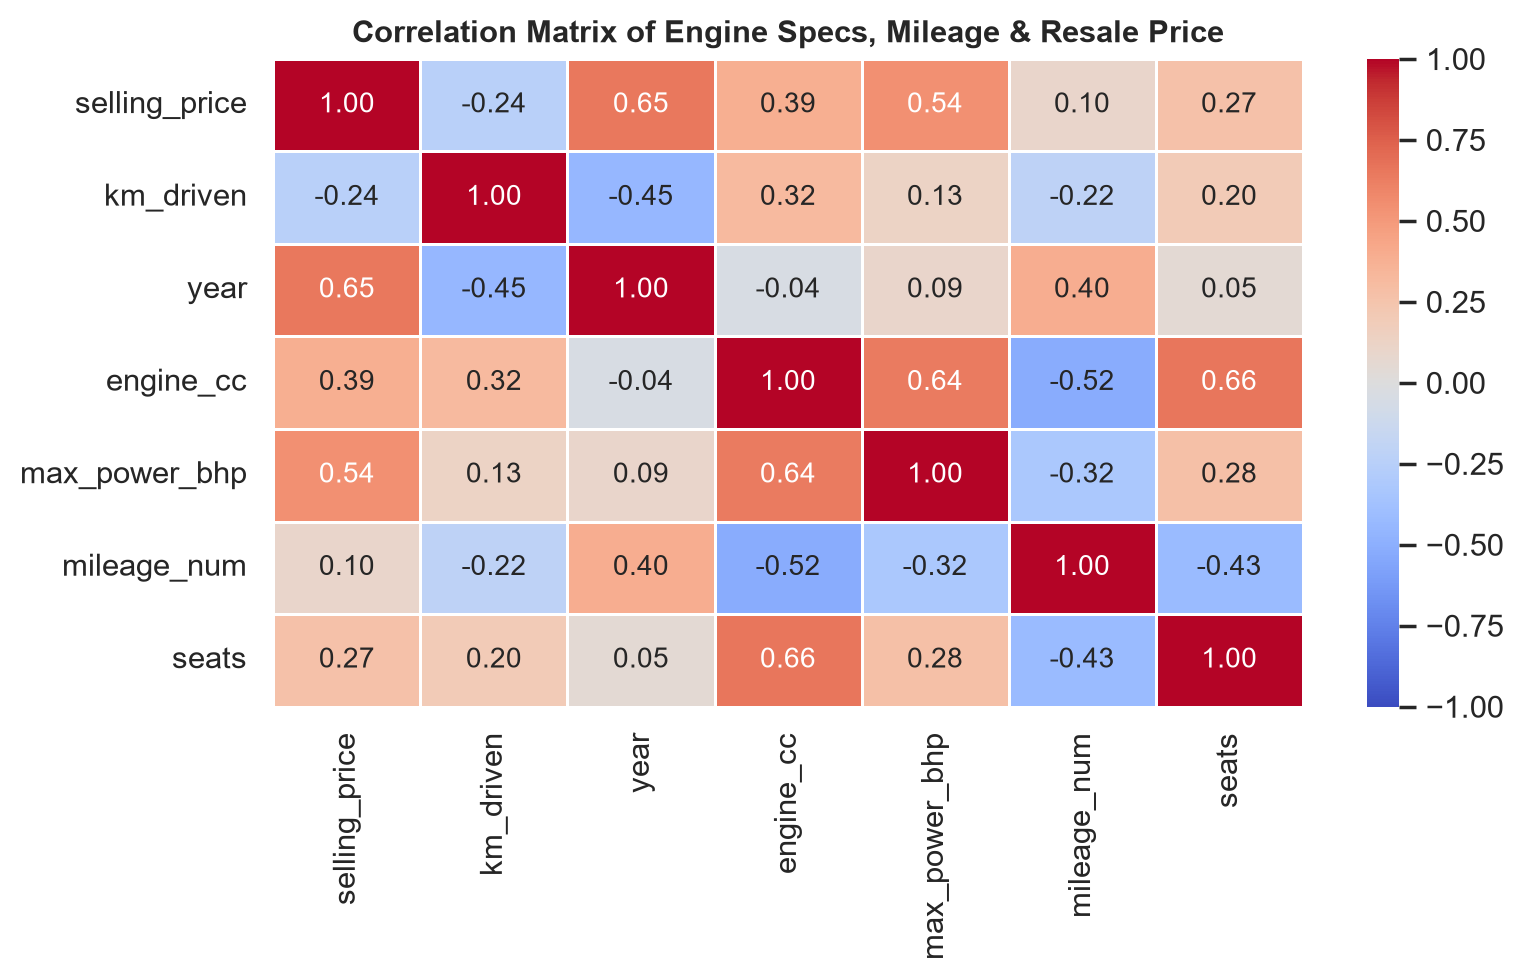

In [9]:
# Display Chart 6: Correlation Heatmap
display(Image('charts/mp1_chart6_correlation_heatmap.png'))

**Observations for Chart 6 (Correlation Heatmap):**
Max power (r = 0.68) and engine displacement (r = 0.53) show the strongest positive linear relationships with selling price, indicating engine performance is the primary driver of automotive valuation. Kilometers driven exhibits a moderate negative correlation (r = -0.38) with price. Mileage (fuel economy) has an inverse relationship with engine size (r = -0.58), confirming the classic engineering trade-off between power and fuel efficiency.

## Step 5: Summary Conclusion in My Own Words

Through this exploratory analysis on the Kaggle CarDekho dataset, three major structural insights emerge:
1. **Depreciation Dynamics:** Resale prices decline rapidly during the first 50,000 kilometers, after which depreciation flattens out into a steady, predictable curve.
2. **Engine Specifications as Valuation Drivers:** Maximum engine horsepower and displacement are the most influential numerical predictors of car price, outpacing simple age metrics.
3. **Market Segmentation:** First owner diesel vehicles from established brands like Toyota and Maruti retain the strongest residual value in the Indian secondary market.